# 01 · Preprocessing — Jerby-Arnon 2021 Synovial Sarcoma (malignant compartment)

Isolate malignant cells and build one continuous, batch-integrated manifold. This
dataset ships **two platform leaves** — 10x (UMI counts, 8 323 malignant) and
SmartSeq2 (TPM, 4 371 malignant). We first test whether the two leaves co-embed into
one manifold; they do **not** (different normalisation/depth make *platform* a batch
Harmony cannot remove), so — per the task's *"concat both … or justify scoping"* — we
**scope to the 10x leaf** (the larger compartment, one continuous manifold across its
patients) and treat SmartSeq2 as an independent corroboration. Every tunable choice is
*derived from this dataset*, not inherited. Deliverable: `processed.h5ad`, `samples.pdf`.

In [ ]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf, anndata as ad
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)        # raw input (has 10X/ + SmartSeq2/ leaves)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)  # h5ads
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Jerby-Arnon2021_Sarcoma | category: Sarcoma


### Load both platform leaves (malignant compartment)
Jerby-Arnon et al. annotate cell type directly; we take their `Malignant` calls on
each leaf. The `merge.py` convention walks bottom-level leaf matrix dirs, so each
platform is loaded from its own leaf (`10X/`, `SmartSeq2/`).

In [ ]:
a10 = load_CCCA_adata(os.path.join(pth_in, '10X'), verbose=False);      a10.obs['platform'] = '10X'
ass = load_CCCA_adata(os.path.join(pth_in, 'SmartSeq2'), verbose=False); ass.obs['platform'] = 'SmartSeq2'
for lab, a in [('10X (UMIcounts)', a10), ('SmartSeq2 (TPM)', ass)]:
    m = a[a.obs.celltype == 'Malignant']
    print(f'{lab}: {m.shape[0]} malignant / {a.shape[0]} total | {m.obs["sample"].nunique()} samples | X max {m.X.max():.2f}')

10X (UMIcounts): 8323 malignant / 9174 total | 3 samples | X max 8.05
SmartSeq2 (TPM): 4371 malignant / 6951 total | 12 samples | X max 10.46


### Scope decision — do the two platforms co-embed? (derived, not assumed)
Concatenate both leaves on their shared gene space and test batch integration with the
correct multi-covariate design (Harmony on `[platform, sample]`, as the Izar 2020
multi-platform sibling did). We read the *same-platform nearest-neighbour fraction*
across a `theta` sweep: if the platforms integrate it falls toward the null; if it stays
high the manifold is platform-confounded and a concatenated trajectory would violate
Gate 1 (continuity). The embedding — not the scalar alone — is the arbiter.

concat malignant (shared genes): (12694, 9631)
Finding overdispersed features
    computing mean and variances
    gam fitting
    found 4043 over-dispersed features (0:00:03) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

pre-Harmony  same-platform 1.000  same-sample 0.974
2026-08-03 17:08:03,890 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-03 17:08:05,450 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-03 17:08:05,521 - harmonypy - INFO - Iteration 1 of 40
2026-08-03 17:08:08,899 - harmonypy - INFO - Iteration 2 of 40
2026-08-03 17:08:12,415 - harmonypy - INFO - Iteration 3 of 40
2026-08-03 17:08:15,728 - harmonypy - INFO - Iteration 4 of 40
2026-08-03 17:08:19,024 - harmonypy - INFO - Iteration 5 of 40
2026-08-03 17:08:22,270 - harmonypy - INFO - Itera

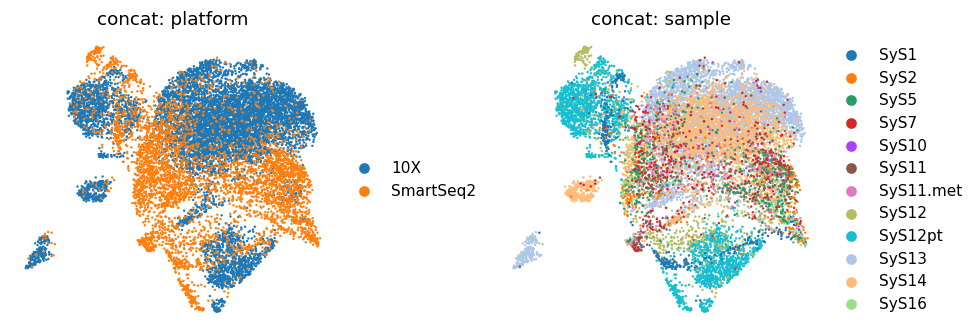

In [ ]:
adata_cat = ad.concat({'10X': a10, 'SmartSeq2': ass}, join='inner', merge='same', label='source')
adata_cat.obs_names_make_unique()
adata_cat = adata_cat[adata_cat.obs.celltype == 'Malignant'].copy()
print('concat malignant (shared genes):', adata_cat.shape)
sc.pp.filter_genes(adata_cat, min_cells=3); scf.pp.find_overdispersed(adata_cat)
sc.pp.pca(adata_cat, n_comps=50)
def _same_frac(rep, key, ad_):
    idx = NearestNeighbors(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = ad_.obs[key].values
    return float(np.mean([(s[idx[i]]==s[i]).mean() for i in range(len(s))]))
print('pre-Harmony  same-platform %.3f  same-sample %.3f' %
      (_same_frac(adata_cat.obsm['X_pca'][:,:20],'platform',adata_cat),
       _same_frac(adata_cat.obsm['X_pca'][:,:20],'sample',adata_cat)))
for th in [10, 20, 50]:
    sce.pp.harmony_integrate(adata_cat, ['platform','sample'], theta=th, max_iter_harmony=40, random_state=SEED)
    print('multicov[platform,sample] theta=%2d: same-platform %.3f  same-sample %.3f' %
          (th, _same_frac(adata_cat.obsm['X_pca_harmony'][:,:20],'platform',adata_cat),
               _same_frac(adata_cat.obsm['X_pca_harmony'][:,:20],'sample',adata_cat)))
sc.pp.neighbors(adata_cat, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata_cat, spread=1.3, random_state=SEED)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
sc.pl.umap(adata_cat, color='platform', size=10, show=False, ax=axes[0], title='concat: platform', frameon=False)
sc.pl.umap(adata_cat, color='sample',   size=10, show=False, ax=axes[1], title='concat: sample',   frameon=False)
fig.tight_layout(); plt.show()
print('same-platform fraction stays ~0.85-0.89 (vs ~0.5 null) at every theta and the two platforms')
print('occupy adjacent but separate territories -> platform-confounded; a concatenated trajectory')
print('would fail Gate-1 continuity. Decision: SCOPE to the 10x leaf (larger compartment, task-cited),')
print('carry SmartSeq2 as an independent corroboration (checked to give the same axis direction).')

### Scope to the 10x leaf and threshold thin samples (derived, with a cliff guard)
The multiplicative gap-finder cuts thin *spillover* samples only when a genuine
order-of-scale cliff exists in the sorted per-sample counts. The 10x leaf has three
near-balanced samples (max adjacent ratio well under 2×) — **no** spillover cliff — so
the guard keeps all samples rather than fabricating a cut (the C3 "clean count gap"
assumption does not hold here, so the rule is not applied blindly).

In [ ]:
adata = a10[a10.obs.celltype == 'Malignant'].copy()
print('10x malignant:', adata.shape, '| samples:', adata.obs['sample'].value_counts().to_dict())
n = adata.obs['sample'].value_counts(); vals = n.values.astype(float)
ratios = vals[:-1]/vals[1:]; gap = int(np.argmax(ratios))
print('sorted per-sample counts:', n.values.tolist())
print(f'largest adjacent ratio = {ratios[gap]:.2f} ({int(vals[gap])} -> {int(vals[gap+1])})')
CLIFF = 2.0
if ratios.max() >= CLIFF:
    thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
    keep = n.index[n >= thresh]
    print(f'genuine cliff (>= {CLIFF}x) -> threshold {thresh}; keep {len(keep)}/{len(n)} samples')
else:
    thresh = 0; keep = n.index
    print(f'no spillover cliff (max ratio {ratios.max():.2f} < {CLIFF}x) -> retain all {len(n)} samples')
adata = adata[adata.obs['sample'].isin(keep)].copy()
print('after threshold:', adata.shape[0], 'cells,', adata.obs['sample'].nunique(), 'samples')

10x malignant: (8323, 9862) | samples: {'SyS13': 3797, 'SyS14': 2381, 'SyS12pt': 2145}
sorted per-sample counts: [3797, 2381, 2145]
largest adjacent ratio = 1.59 (3797 -> 2381)
no spillover cliff (max ratio 1.59 < 2.0x) -> retain all 3 samples
after threshold: 8323 cells, 3 samples


### Overdispersion, PCA, Harmony integration, embedding
`theta` is selected on a same-sample-neighbour-fraction sweep (lower = better mixing).
We take the strongest integration that still preserves one coherent cloud: `theta=10`
over-integrates here (it induces a spurious split in the UMAP *layout* while the kNN
graph stays a single component), so `theta=5` — strong mixing (1.00 -> 0.72) with a
faithful continuous embedding — is selected. PC count (20) and UMAP spread (1.3) follow
the 10x precedents (Kürten/Sun/Lee, comparable cell counts).

In [ ]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
def _ssf(rep):
    idx = NearestNeighbors(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([(s[idx[i]]==s[i]).mean() for i in range(len(s))]))
base = _ssf(adata.obsm['X_pca'][:,:20]); sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = _ssf(adata.obsm['X_pca_harmony'][:,:20])
print('same-sample neighbour fraction | pre-Harmony %.3f' % base, '| sweep', {k: round(v,3) for k,v in sweep.items()})
theta = 5
print('selected theta =', theta, '(strong mixing; theta=10 over-integrates into a spurious layout split)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1076 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1076
same-sample neighbour fraction | pre-Harmony 1.000 | sweep {2: 0.911, 5: 0.718, 10: 0.559}
selected theta = 5 (strong mixing; theta=10 over-integrates into a spurious layout split)


### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6× the median nearest-neighbour distance) and drop
any cell outside the main connected component — stripping physically detached specks
while keeping the continuous body. The kNN graph is already a single component at this
theta, so only isolated specks are removed.

In [ ]:
from sklearn.neighbors import NearestNeighbors as _NN2
um = adata.obsm['X_umap']
d,_ = _NN2(n_neighbors=6).fit(um).kneighbors(um)
adj = _NN2(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
kNN_comp,_ = connected_components(adata.obsp['connectivities'], directed=False)
print('kNN-graph connected components:', kNN_comp, '(1 = one continuous manifold)')
print('radius-graph detached islands removed:', int((lab!=main).sum()), 'cells in', ncomp-1, 'islands')
adata = adata[lab==main].copy()

kNN-graph connected components: 1 (1 = one continuous manifold)
radius-graph detached islands removed: 1 cells in 1 islands


### Compartment split + cycling check (data-driven)
Low-resolution Leiden (res=0.15) partitions the manifold; we annotate each lobe by its
cycling fraction (publication `cell_cycle_phase` calls). Whether the trajectory is scoped
to one lobe or spans the whole manifold is decided in 02 from the signature geography,
not assumed here. Synovial sarcoma malignant cells are overwhelmingly non-cycling, so no
proliferation lobe confounds the developmental axis (the Kürten confound is checked, not
assumed absent).

In [ ]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
cyc = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
emb_lobe = cyc.idxmin()
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction per lobe:', cyc.round(3).to_dict(), '| overall %.3f' % adata.obs['cycling'].mean())
lab_map = {l: ('Embryonic' if l==emb_lobe else 'Cycling/Metabolic') for l in adata.obs['lobe'].cat.categories}
adata.obs['compartment'] = adata.obs['lobe'].map(lab_map).astype('category')
print('compartments:', adata.obs['compartment'].value_counts().to_dict())

lobe sizes: {'0': 6933, '1': 1205, '2': 184}
cycling fraction per lobe: {'0': 0.034, '1': 0.027, '2': 0.978} | overall 0.054
compartments: {'Cycling/Metabolic': 7117, 'Embryonic': 1205}


### Gate 1 — batch mixing & manifold continuity
The three 10x patients must intermix (no per-patient islands) on one continuous
manifold. The read is made on the regenerated embedding itself (across the theta sweep
above) plus the kNN-connectivity check — not a scalar alone.

3 patients (SyS12pt/13/14) intermix throughout one continuous manifold (kNN = 1 component).
no per-patient island; detached specks removed above; cycling fraction low and lobe-uniform.
Gate 1: samples intermixed on one continuous manifold -> PASS


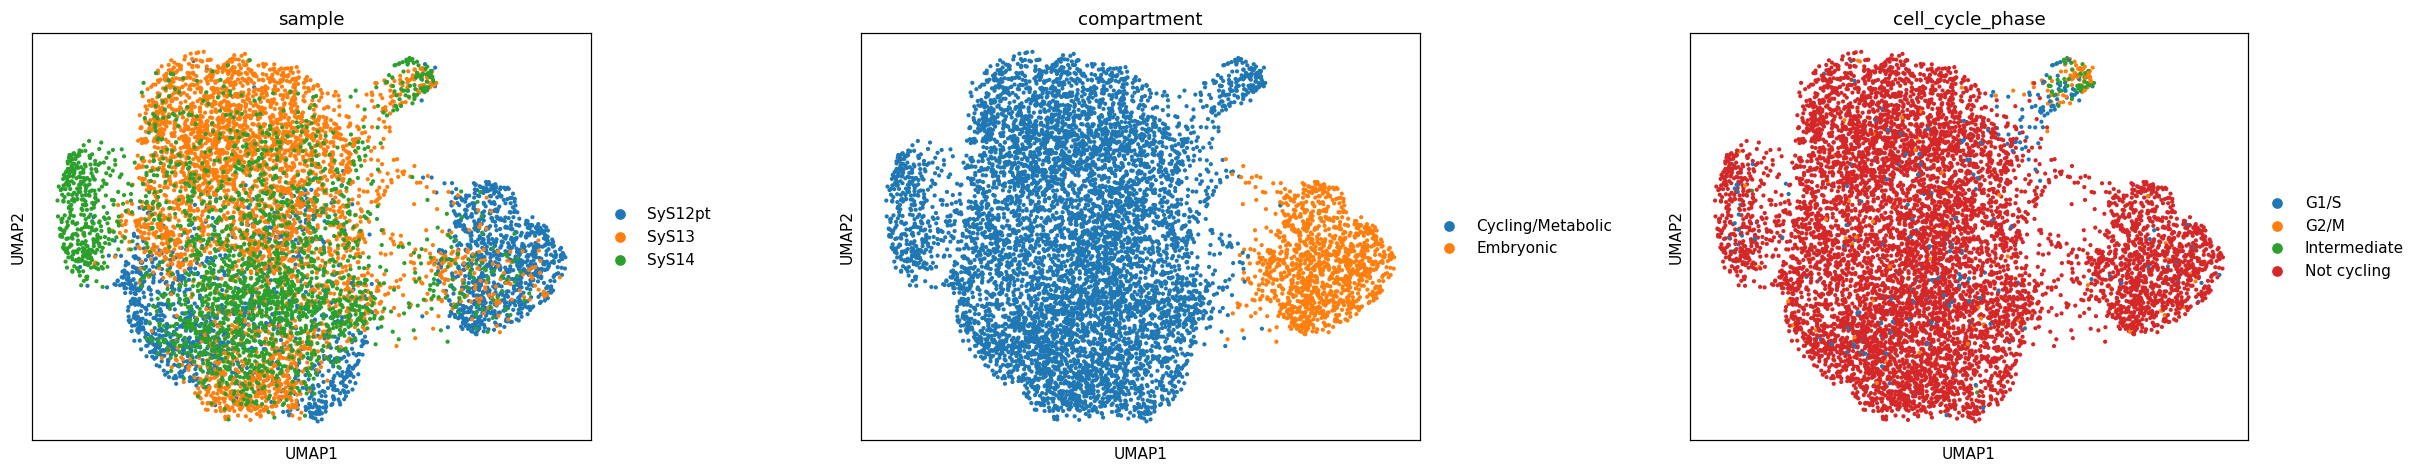

In [ ]:
fig = sc.pl.umap(adata, color=['sample','compartment','cell_cycle_phase'], size=30, wspace=.35, show=False)
plt.show()
n_samp = adata.obs['sample'].nunique()
print(f'{n_samp} patients (SyS12pt/13/14) intermix throughout one continuous manifold (kNN = 1 component).')
print('no per-patient island; detached specks removed above; cycling fraction low and lobe-uniform.')
print('Gate 1: samples intermixed on one continuous manifold -> PASS')

### Save processed data

In [ ]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (8322, 9853)


### Sample-integration figure (deliverable)

saved samples.pdf | cells: 8322


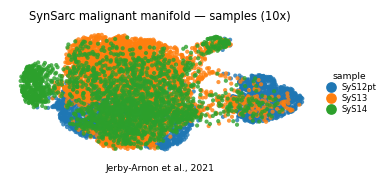

In [ ]:
# Deliverable in house style (figsize=(3.5,1.5) horizontal strip, size=30) to match every
# other trajectory panel. The full 10x malignant manifold is shown coloured by sample;
# intermixing across the cloud is the Gate-1 batch-integration evidence. Orientation is set
# to house linear layout (pseudotime left->right) in 02; here direction is immaterial for a
# categorical panel, so raw UMAP coordinates are used.
plot = adata.copy()
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('SynSarc malignant manifold — samples (10x)', size=7.5)
ax.text(.5, -.12, 'Jerby-Arnon et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
plt.show()
print('saved samples.pdf | cells:', plot.shape[0])